# Assignment 10
Due Nov. 18

Yazdan Zinati 
260928077   

Dataset with brain atlas A: use the Oasis dataset for classification of male and female
individuals based on brain scans.

In [1]:
import numpy as np
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib


def fetch_oasis_dataset(n_rois):
    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
    yeo = datasets.fetch_atlas_schaefer_2018(
        n_rois=n_rois
    )  # this needs to be modified for some tasks
    print(
        "%i regions found in this atlas"
        % (len(np.unique(nib.load(yeo.maps).get_fdata().ravel())) - 1)
    )
    masker = NiftiLabelsMasker(
        labels_img=yeo.maps, standardize=True, memory="nilearn_cache"
    )
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = np.array(
        brain_data.ext_vars.mf == "F", dtype=int
    )  # gives 1 for females and 0 for males

    return input_variables, output_variable

Note for Tasks 1/2/5 and 6/7/10: PolynomialFeatures will generate many features at higher
degrees, so use only the first 50 columns of the input data (input_variables[:, 0:50]). If the
higher degree polynomial features still cause problems, you can restrict your plot to the
lower degrees (eg 1-4).

Task 1- Use sklearn.preprocessing.PolynomialFeatures() to fit LogisticRegression(default
parameters) based on 100 brain regions of interest (n_rois=100). Use the first 90 subjects
as the training set. Fit 5 different models with increasingly representational capacity
(degree=1-5). Next, evaluate each fitted classification model on the unseen 10 subjects,
and plot the classification accuracy (x axis=5 different models, y axis=prediction accuracy;
plot train/test as lines on the same plot using different colours).

100 regions found in this atlas


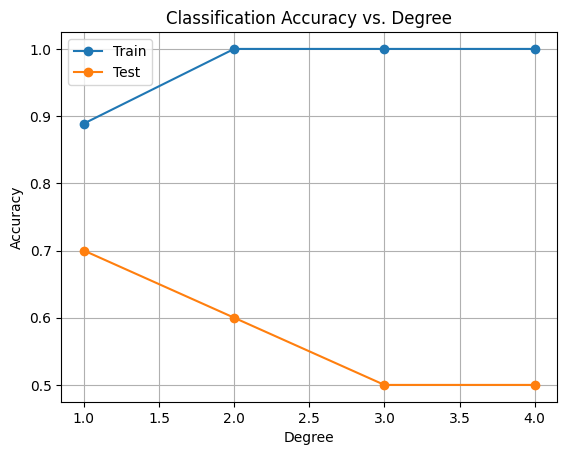

In [2]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

n_rois = 100
input_variables, output_variable = fetch_oasis_dataset(n_rois)

X = input_variables[:, :50]
y = output_variable

# Split into train/test
X_train, X_test = X[:90], X[90:]
y_train, y_test = y[:90], y[90:]

degrees = [1, 2, 3, 4]
train_accuracies = []
test_accuracies = []

for degree in degrees:

    pf = PolynomialFeatures(degree=degree)
    X_train_poly = pf.fit_transform(X_train)
    X_test_poly = pf.transform(X_test)

    lr = LogisticRegression()
    lr.fit(X_train_poly, y_train)

    # Predict and calculate accuracy
    y_train_pred = lr.predict(X_train_poly)
    y_test_pred = lr.predict(X_test_poly)

    train_accuracies.append(accuracy_score(y_train, y_train_pred))
    test_accuracies.append(accuracy_score(y_test, y_test_pred))

plt.figure()
plt.plot(degrees, train_accuracies, label="Train", marker="o")
plt.plot(degrees, test_accuracies, label="Test", marker="o")
plt.xlabel("Degree")
plt.ylabel("Accuracy")
plt.title("Classification Accuracy vs. Degree")
plt.legend()
plt.grid(True)
plt.show()

Task 2- Same as task 1, but with Bayesian linear regression
(sklearn.linear_model.BayesianRidge()), binary outcome can be encoded as +1 and -1. You
will have to convert the continuous prediction back to binary (threshold it at zero) to
calculate the test accuracy.

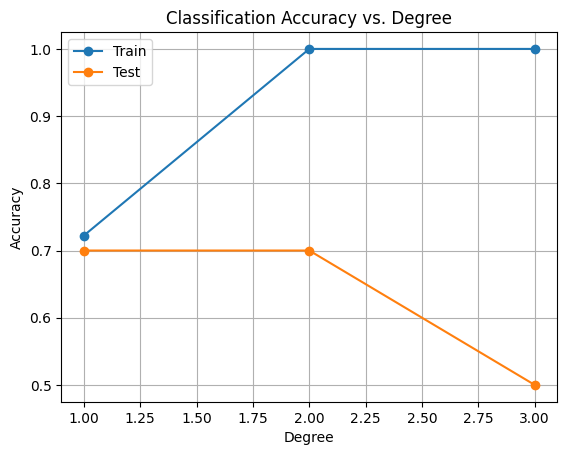

In [5]:
from sklearn.linear_model import BayesianRidge

degrees = [1, 2, 3,]

y_continuous = 2 * output_variable - 1  # 0 -> -1 and 1 -> 1
y_train, y_test = y_continuous[:90], y_continuous[90:]

train_accuracies, test_accuracies = [], []

for degree in degrees:
    pf = PolynomialFeatures(degree=degree)
    X_train_poly = pf.fit_transform(X_train)
    X_test_poly = pf.transform(X_test)

    lr = BayesianRidge()
    lr.fit(X_train_poly, y_train)

    y_train_pred = np.sign(
        lr.predict(X_train_poly)
    )  # returns -1 if x < 0, 0 if x==0, 1 if x > 0.
    y_test_pred = np.sign(lr.predict(X_test_poly))

    train_accuracies.append(accuracy_score(y_train, y_train_pred))
    test_accuracies.append(accuracy_score(y_test, y_test_pred))

plt.figure()
plt.plot(degrees, train_accuracies, label="Train", marker="o")
plt.plot(degrees, test_accuracies, label="Test", marker="o")
plt.xlabel("Degree")
plt.ylabel("Accuracy")
plt.title("Classification Accuracy vs. Degree")
plt.legend()
plt.grid(True)
plt.show()

Task 3- Same as task 1, but PolynomialFeatures(degree=2) and LogisticRegression(), after
applying k-means clustering on the training subjects (n_clusters=1-20, think of fixing the
random_state in an appropriate way due to non-convexity). Plot the classification accuracy
on the training and test sets (x axis=number of clusters, y axis=prediction accuracy; plot
train/test as lines on the same plot using different colours).

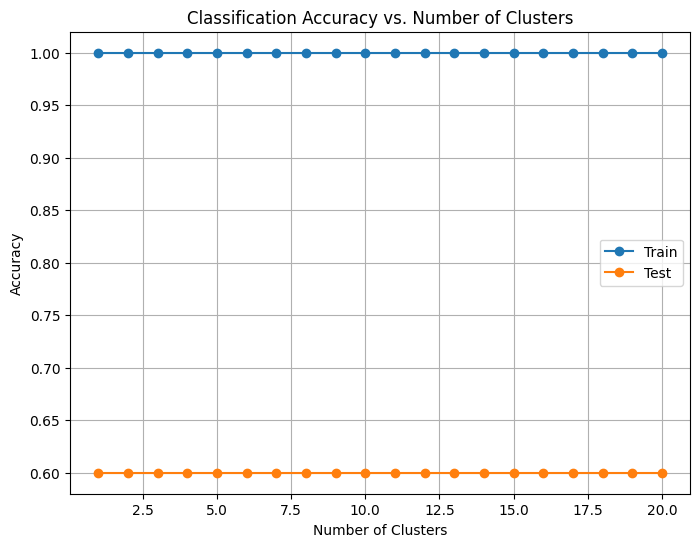

In [6]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import OneHotEncoder

degree = 2
train_accuracies = []
test_accuracies = []

pf = PolynomialFeatures(degree=degree)
X_train_poly = pf.fit_transform(X_train)
X_test_poly = pf.transform(X_test)

for n_clusters in range(1, 21):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, max_iter=500)
    train_clusters = kmeans.fit_predict(X_train_poly)
    test_clusters = kmeans.predict(X_test_poly)

    encoder = OneHotEncoder(sparse_output=False)
    train_clusters_onehot = encoder.fit_transform(train_clusters.reshape(-1, 1))
    test_clusters_onehot = encoder.transform(test_clusters.reshape(-1, 1))

    X_train_augmented = np.hstack([X_train_poly, train_clusters_onehot])
    X_test_augmented = np.hstack([X_test_poly, test_clusters_onehot])

    lr = LogisticRegression(C=1.0, random_state=42)
    lr.fit(X_train_augmented, y_train)

    y_train_pred = lr.predict(X_train_augmented)
    y_test_pred = lr.predict(X_test_augmented)

    train_accuracies.append(accuracy_score(y_train, y_train_pred))
    test_accuracies.append(accuracy_score(y_test, y_test_pred))

plt.figure(figsize=(8, 6))
plt.plot(list(range(1, 21)), train_accuracies, label="Train", marker="o")
plt.plot(list(range(1, 21)), test_accuracies, label="Test", marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Accuracy")
plt.title("Classification Accuracy vs. Number of Clusters")
plt.legend()
plt.grid(True)
plt.show()

Task 4- Same as task 1, but PolynomialFeatures(degree=2) and LogisticRegression(), after
applying Gaussian mixture modelling clustering on the training subjects (n_clusters=1-20,
think of fixing the random_state in an appropriate way due to non-convexity). Plot theclassification accuracy on the training and test sets (x axis=number of clusters, y
axis=prediction accuracy; plot train/test as lines on the same plot using different colours).

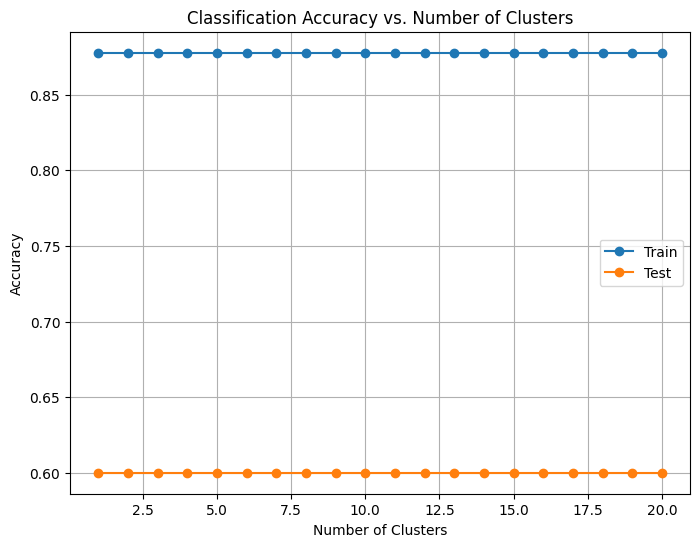

In [7]:
from sklearn.mixture import GaussianMixture

train_accuracies = []
test_accuracies = []

for n_clusters in range(1, 21):
    gmm = GaussianMixture(n_components=n_clusters, random_state=42)
    train_clusters = gmm.fit_predict(X_train_poly)
    test_clusters = gmm.predict(X_test_poly)

    encoder = OneHotEncoder(sparse_output=False)
    train_clusters_onehot = encoder.fit_transform(train_clusters.reshape(-1, 1))
    test_clusters_onehot = encoder.transform(test_clusters.reshape(-1, 1))

    X_train_augmented = np.hstack([X_train_poly, train_clusters_onehot])
    X_test_augmented = np.hstack([X_test_poly, test_clusters_onehot])

    lr = LogisticRegression(C=0.01, random_state=42)
    lr.fit(X_train_augmented, y_train)

    y_train_pred = lr.predict(X_train_augmented)
    y_test_pred = lr.predict(X_test_augmented)

    train_accuracies.append(accuracy_score(y_train, y_train_pred))
    test_accuracies.append(accuracy_score(y_test, y_test_pred))

plt.figure(figsize=(8, 6))
plt.plot(list(range(1, 21)), train_accuracies, label="Train", marker="o")
plt.plot(list(range(1, 21)), test_accuracies, label="Test", marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Accuracy")
plt.title("Classification Accuracy vs. Number of Clusters")
plt.legend()
plt.grid(True)
plt.show()

Task 5- Like task 2, but plotting on y axis the number of miliseconds that are needed to do
BayesianRidge().fit() for each degree (x axis).

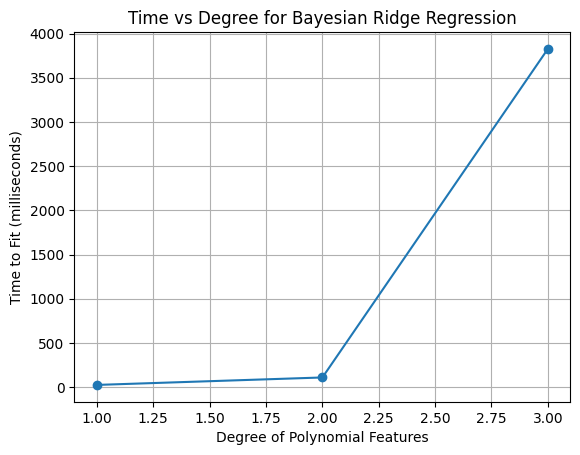

In [8]:
import time

degrees = [1, 2, 3]

y_continuous = 2 * output_variable - 1  # 0 -> -1 and 1 -> 1
y_train, y_test = y_continuous[:90], y_continuous[90:]

times = []

for degree in degrees:
    pf = PolynomialFeatures(degree=degree)
    X_train_poly = pf.fit_transform(X_train)
    X_test_poly = pf.transform(X_test)

    lr = BayesianRidge()

    start_time = time.time()
    lr.fit(X_train_poly, y_train)
    end_time = time.time()
    fit_time = (end_time - start_time) * 1000 # to ms

    times.append(fit_time)

plt.figure()
plt.plot(degrees, times, marker="o")
plt.xlabel("Degree of Polynomial Features")
plt.ylabel("Time to Fit (milliseconds)")
plt.title("Time vs Degree for Bayesian Ridge Regression")
plt.grid(True)
plt.show()

Dataset B: use the nilearn Oasis dataset to predict a continuous outcome (age) based on
structural brain scans

In [9]:
import os

from sklearn.preprocessing import StandardScaler


def load_craddock_local(base_path):
    # Dictionary to hold the dataset information
    craddock_data = {
        "scorr_mean": os.path.join(base_path, "scorr05_mean_all.nii.gz"),
        "tcorr_mean": os.path.join(base_path, "tcorr05_mean_all.nii.gz"),
        "scorr_2level": os.path.join(base_path, "scorr05_2level_all.nii.gz"),
        "tcorr_2level": os.path.join(base_path, "tcorr05_2level_all.nii.gz"),
        "random": os.path.join(base_path, "random_all.nii.gz"),
        "description": "Craddock 2012 atlas parcellation dataset emphasizing spatial and temporal homogeneity.",
    }
    return craddock_data


def fetch_second_dataset(n_rois, debug=False):

    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)

    brain_data_dir = "/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/A3/craddock/"
    crad = load_craddock_local(brain_data_dir)

    atlas_nii = index_img(crad["scorr_mean"], n_rois)
    masker = NiftiLabelsMasker(labels_img=atlas_nii, standardize=True)
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = StandardScaler().fit_transform(brain_data.ext_vars.age[:, None])[
        :, 0
    ]  # gives subject age on standard units after z-scoring
    return input_variables, output_variable

Note: use Ridge() and the R2 score (sklearn.metrics.r2_score) instead of
LogisticRegression and accuracy. Use the lowest resolution atlas.

6- analogous to task 1 but predicting continuous subject age

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_ridge.py:253: LinAlgWarning: Ill-conditioned matrix (rcond=4.05127e-09): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(


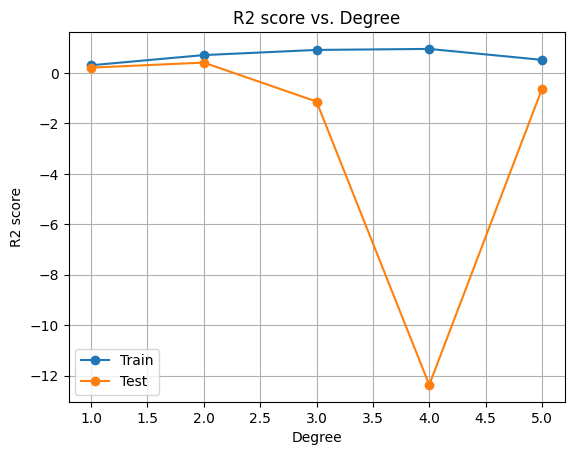

In [10]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

n_rois = 0
input_variables, output_variable = fetch_second_dataset(n_rois)

X = input_variables[:, :50]
y = output_variable

X_train, X_test = X[:90], X[90:]
y_train, y_test = y[:90], y[90:]

degrees = [1, 2, 3, 4, 5]
train_accuracies = []
test_accuracies = []

for degree in degrees:

    pf = PolynomialFeatures(degree=degree)
    X_train_poly = pf.fit_transform(X_train)
    X_test_poly = pf.transform(X_test)

    lr = Ridge()
    lr.fit(X_train_poly, y_train)

    y_train_pred = lr.predict(X_train_poly)
    y_test_pred = lr.predict(X_test_poly)

    train_accuracies.append(r2_score(y_train, y_train_pred))
    test_accuracies.append(r2_score(y_test, y_test_pred))

plt.figure()
plt.plot(degrees, train_accuracies, label="Train", marker="o")
plt.plot(degrees, test_accuracies, label="Test", marker="o")
plt.xlabel("Degree")
plt.ylabel("R2 score")
plt.title("R2 score vs. Degree")
plt.legend()
plt.grid(True)
plt.show()

7- analogous to task 2 but predicting continuous subject age. Now that the target is
continuous you don’t have to threshold the prediction.

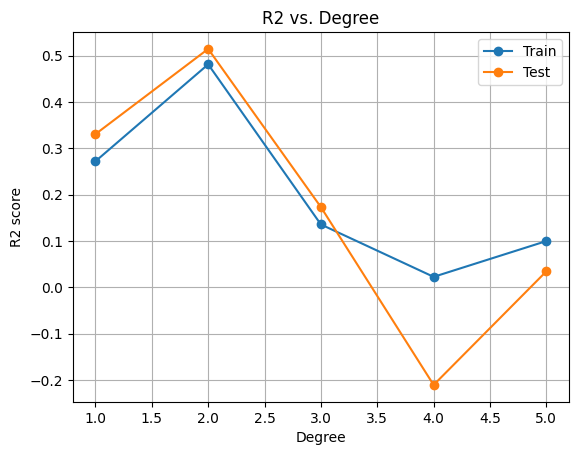

In [11]:
from sklearn.linear_model import BayesianRidge

degrees = [1, 2, 3, 4, 5]

y_train, y_test = y[:90], y[90:]

train_accuracies, test_accuracies = [], []

for degree in degrees:
    pf = PolynomialFeatures(degree=degree)
    X_train_poly = pf.fit_transform(X_train)
    X_test_poly = pf.transform(X_test)

    lr = BayesianRidge()
    lr.fit(X_train_poly, y_train)

    y_train_pred = lr.predict(X_train_poly)
    y_test_pred = lr.predict(X_test_poly)

    train_accuracies.append(r2_score(y_train, y_train_pred))
    test_accuracies.append(r2_score(y_test, y_test_pred))

plt.figure()
plt.plot(degrees, train_accuracies, label="Train", marker="o")
plt.plot(degrees, test_accuracies, label="Test", marker="o")
plt.xlabel("Degree")
plt.ylabel("R2 score")
plt.title("R2 vs. Degree")
plt.legend()
plt.grid(True)
plt.show()

8- analogous to task 3 but predicting continuous subject age

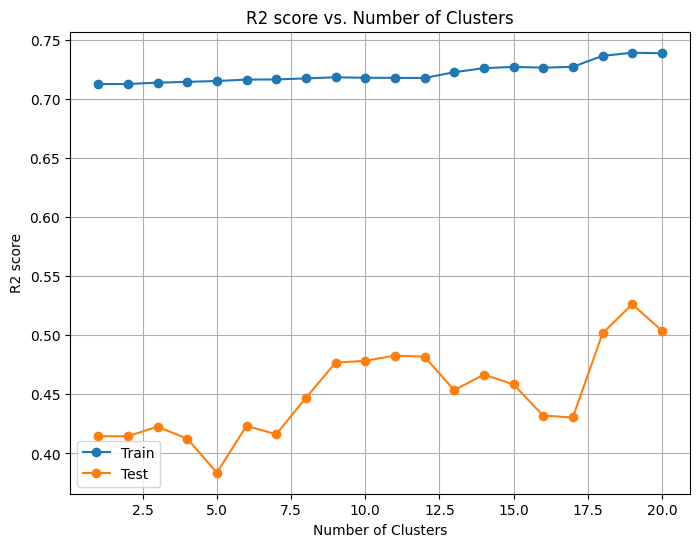

In [13]:
degree = 2
train_accuracies = []
test_accuracies = []

pf = PolynomialFeatures(degree=degree)
X_train_poly = pf.fit_transform(X_train)
X_test_poly = pf.transform(X_test)

for n_clusters in range(1, 21):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, max_iter=500)
    train_clusters = kmeans.fit_predict(X_train_poly)
    test_clusters = kmeans.predict(X_test_poly)

    encoder = OneHotEncoder(sparse_output=False)
    train_clusters_onehot = encoder.fit_transform(train_clusters.reshape(-1, 1))
    test_clusters_onehot = encoder.transform(test_clusters.reshape(-1, 1))

    X_train_augmented = np.hstack([X_train_poly, train_clusters_onehot])
    X_test_augmented = np.hstack([X_test_poly, test_clusters_onehot])

    lr = Ridge(random_state=42)
    lr.fit(X_train_augmented, y_train)

    y_train_pred = lr.predict(X_train_augmented)
    y_test_pred = lr.predict(X_test_augmented)

    train_accuracies.append(r2_score(y_train, y_train_pred))
    test_accuracies.append(r2_score(y_test, y_test_pred))

plt.figure(figsize=(8, 6))
plt.plot(list(range(1, 21)), train_accuracies, label="Train", marker="o")
plt.plot(list(range(1, 21)), test_accuracies, label="Test", marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("R2 score")
plt.title("R2 score vs. Number of Clusters")
plt.legend()
plt.grid(True)
plt.show()

9- analogous to task 4 but predicting continuous subject age

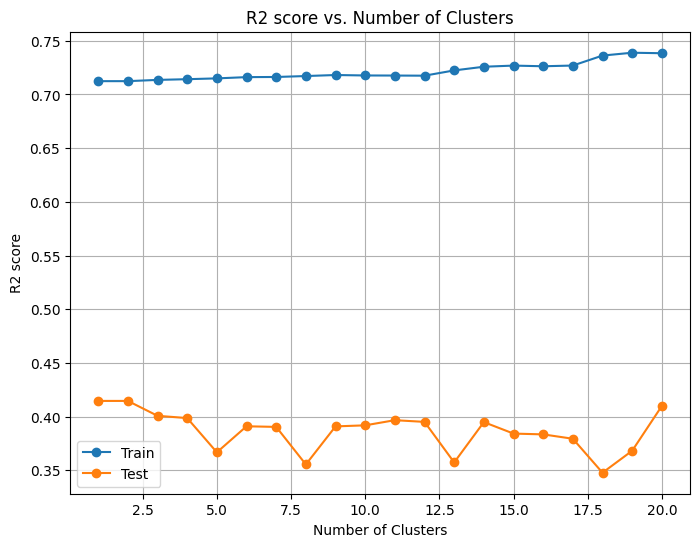

In [14]:
train_accuracies = []
test_accuracies = []

for n_clusters in range(1, 21):
    gmm = GaussianMixture(n_components=n_clusters, random_state=42)
    train_clusters = gmm.fit_predict(X_train_poly)
    test_clusters = gmm.predict(X_test_poly)

    encoder = OneHotEncoder(sparse_output=False)
    train_clusters_onehot = encoder.fit_transform(train_clusters.reshape(-1, 1))
    test_clusters_onehot = encoder.transform(test_clusters.reshape(-1, 1))

    X_train_augmented = np.hstack([X_train_poly, train_clusters_onehot])
    X_test_augmented = np.hstack([X_test_poly, test_clusters_onehot])

    lr = Ridge(random_state=42)
    lr.fit(X_train_augmented, y_train)

    y_train_pred = lr.predict(X_train_augmented)
    y_test_pred = lr.predict(X_test_augmented)

    train_accuracies.append(r2_score(y_train, y_train_pred))
    test_accuracies.append(r2_score(y_test, y_test_pred))

plt.figure(figsize=(8, 6))
plt.plot(list(range(1, 21)), train_accuracies, label="Train", marker="o")
plt.plot(list(range(1, 21)), test_accuracies, label="Test", marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("R2 score")
plt.title("R2 score vs. Number of Clusters")
plt.legend()
plt.grid(True)
plt.show()

10- analogous to task 5 but predicting continuous subject age

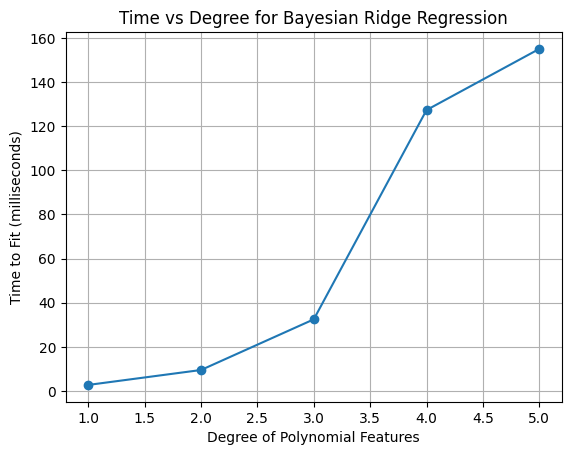

In [17]:
import time

degrees = [1, 2, 3, 4, 5]

y_train, y_test = y[:90], y[90:]

times = []

for degree in degrees:
    pf = PolynomialFeatures(degree=degree)
    X_train_poly = pf.fit_transform(X_train)
    X_test_poly = pf.transform(X_test)

    lr = BayesianRidge()

    start_time = time.time()
    lr.fit(X_train_poly, y_train)
    end_time = time.time()
    fit_time = (end_time - start_time) * 1000  # to ms

    times.append(fit_time)

plt.figure()
plt.plot(degrees, times, marker="o")
plt.xlabel("Degree of Polynomial Features")
plt.ylabel("Time to Fit (milliseconds)")
plt.title("Time vs Degree for Bayesian Ridge Regression")
plt.grid(True)
plt.show()